# C02 — Corrida antiga × ressequenciamento, célula a célula

## Objetivo

Medir o que o ressequenciamento mudou em cada célula e em cada gene, usando
o fato de que as duas corridas leem as mesmas bibliotecas físicas: o mesmo
barcode é a mesma gota.

## Pergunta

A profundidade extra trouxe mais moléculas? E, em particular, mais
transcritos de citocina?

## Dados

* corrida antiga — `data/raw_h5ad/*.h5ad` (matriz filtrada do Cell Ranger,
  antes de qualquer QC);
* ressequenciamento — `data/allOuts/*/outs/filtered_feature_bc_matrix.h5`, e
  a matriz bruta para os barcodes que deixaram de ser chamados como célula.

## Método

1. Identidade das bibliotecas por sobreposição de barcodes, e sexo do doador.
2. Diferenças na chamada de células.
3. Ganho de UMIs e genes por célula pareada; profundidade antiga estimada.
4. Reprodutibilidade das contagens entre corridas.
5. Ganho por gene em função do nível de expressão.
6. Citocinas.

## Decisões

* A comparação usa as matrizes do Cell Ranger, sem filtro de QC, para isolar
  o efeito da profundidade.
* A corrida antiga não tem `molecule_info`, web summary nem versão do
  pipeline registrada. Diferenças entre corridas podem vir da profundidade
  ou do processamento; onde não dá para separar, isso é dito.
* 14 bibliotecas de 7 pacientes. Os totais agregados são dominados pelas
  bibliotecas grandes (PB21), então os resultados são sempre dados também por
  biblioteca. O único teste formal é o pareado estimulado × não estimulado
  dentro de paciente (n=7).

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from functions import compare, config, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "C02_antigo_vs_novo"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
PANEL = config.CYTOKINES + config.LINEAGE_TFS

## Leitura única das 14 bibliotecas

Uma passada por biblioteca acumula tudo o que as seções seguintes usam; as
matrizes não ficam na memória.

In [2]:
features = io.reference_features()
names = features["gene_name"].to_numpy()
n_genes = len(names)
panel_idx = io.gene_index(names, PANEL)
assert set(panel_idx) == set(PANEL), "gene do painel fora da referência"

bc_old, bc_new = {}, {}
cells_rows, lib_rows, panel_rows = [], [], []
G = {k: np.zeros((len(LIBS), n_genes), dtype=np.int32)
     for k in ("pos_old", "pos_new", "umi_old", "umi_new", "lost")}
only_new_tab, only_old_tab = [], []

for li, lib in enumerate(LIBS):
    P = compare.load_pair(lib)
    bc_old[lib], bc_new[lib] = P["barcodes_old"], P["barcodes_new"]

    uo, go = compare.per_cell(P["Xo"])
    un, gn = compare.per_cell(P["Xn"])
    cells_rows.append(pd.DataFrame({
        "library_id": lib, "barcode": P["barcodes"],
        "umis_antiga": uo, "umis_nova": un, "genes_antiga": go, "genes_nova": gn}))

    # contagens por gene nas células pareadas
    G["pos_old"][li], G["umi_old"][li] = compare.per_gene(P["Xo"])
    G["pos_new"][li], G["umi_new"][li] = compare.per_gene(P["Xn"])
    D = (P["Xn"].astype(np.int64) - P["Xo"].astype(np.int64)).tocoo()
    neg = D.data < 0
    np.add.at(G["lost"][li], D.col[neg], (-D.data[neg]).astype(np.int32))

    # entradas (célula, gene) com 1 UMI na antiga: quantas zeram na nova
    Xo_coo = P["Xo"].tocoo()
    um = Xo_coo.data == 1
    novo = np.asarray(P["Xn"][Xo_coo.row[um], Xo_coo.col[um]]).ravel()
    ec = compare.entry_consistency(P["Xo"], P["Xn"])

    # barcodes chamados como célula em só uma corrida
    pos_new = {b: i for i, b in enumerate(P["barcodes_new"])}
    pos_old = {b: i for i, b in enumerate(P["barcodes_old"])}
    un_all, gn_all = compare.per_cell(P["Xn_all"])
    uo_all, go_all = compare.per_cell(P["Xo_all"])
    idx_on = np.array([pos_new[b] for b in P["only_new"]], dtype=int)
    idx_oo = np.array([pos_old[b] for b in P["only_old"]], dtype=int)
    only_new_tab.append(pd.DataFrame({"library_id": lib, "barcode": P["only_new"],
                                      "umis_nova": un_all[idx_on], "genes_nova": gn_all[idx_on]}))
    only_old_tab.append(pd.DataFrame({"library_id": lib, "barcode": P["only_old"],
                                      "umis_antiga": uo_all[idx_oo], "genes_antiga": go_all[idx_oo]}))

    # a cópia em data/raw_h5ad confere com a fonte em data/raw?
    h5 = io.read_old_raw_h5ad(lib)
    assert np.array_equal(h5["barcodes"], P["barcodes_old"])
    dif = (P["Xo_all"].astype(np.int64) - h5["X"].astype(np.int64)).tocoo()
    dif_ok = dif.data != 0
    h5_div = {"entradas": int(dif_ok.sum()), "umis": int(dif.data[dif_ok].sum()),
              "genes": sorted(set(names[np.unique(dif.col[dif_ok])]))}
    del h5, dif

    sx_o = compare.sex_signal(P["Xo_all"], names)
    sx_n = compare.sex_signal(P["Xn_all"], names)
    lib_rows.append({
        "raw_h5ad_entradas_divergentes": h5_div["entradas"],
        "raw_h5ad_umis_faltando": h5_div["umis"],
        "raw_h5ad_genes_afetados": ", ".join(h5_div["genes"]),
        "library_id": lib, "celulas_antiga": len(P["barcodes_old"]),
        "celulas_nova": len(P["barcodes_new"]), "pareadas": len(P["barcodes"]),
        "so_antiga": len(P["only_old"]), "so_nova": len(P["only_new"]),
        "umis_medianos_antiga": np.median(uo_all), "umis_medianos_nova": np.median(un_all),
        "unicas_1umi_antiga": int(um.sum()), "unicas_1umi_zeraram": int((novo == 0).sum()),
        "frac_entradas_que_cairam": ec["frac_entradas_que_cairam"],
        "frac_umis_perdidos": ec["frac_umis_perdidos"],
        "XIST_antiga": sx_o["frac_XIST"], "Y_antiga": sx_o["frac_genes_Y"],
        "XIST_nova": sx_n["frac_XIST"], "Y_nova": sx_n["frac_genes_Y"],
    })

    # painel: contagens por célula pareada (só entradas não nulas em alguma corrida)
    for g, j in panel_idx.items():
        co, cn = compare.column(P["Xo"], j), compare.column(P["Xn"], j)
        keep = (co > 0) | (cn > 0)
        if keep.any():
            panel_rows.append(pd.DataFrame({"library_id": lib, "barcode": P["barcodes"][keep],
                                            "gene": g, "antiga": co[keep], "nova": cn[keep]}))
    del P, D, Xo_coo

cells = pd.concat(cells_rows, ignore_index=True)
cells["razao_umis"] = cells["umis_nova"] / cells["umis_antiga"]
cells["razao_genes"] = cells["genes_nova"] / cells["genes_antiga"]
lib = pd.DataFrame(lib_rows).set_index("library_id")
panel = pd.concat(panel_rows, ignore_index=True)
only_new = pd.concat(only_new_tab, ignore_index=True)
only_old = pd.concat(only_old_tab, ignore_index=True)
n_pares = len(cells)
print(f"células pareadas: {F.n(n_pares)} | antiga {F.n(lib['celulas_antiga'].sum())} | "
      f"nova {F.n(lib['celulas_nova'].sum())}")

células pareadas: 37.092 | antiga 37.161 | nova 37.898


### Integridade da cópia `data/raw_h5ad`

A corrida antiga existe em duas formas: a matriz do Cell Ranger em
`data/raw/<biblioteca>/` (fonte, de 7 de junho) e a cópia em h5ad que o
notebook original gravou em `data/raw_h5ad/` (regravada em 15 de julho). As
duas deveriam ser idênticas. Esta análise lê a fonte; a conferência abaixo
diz se a cópia ainda serve.

In [3]:
integ = lib[["raw_h5ad_entradas_divergentes", "raw_h5ad_umis_faltando", "raw_h5ad_genes_afetados"]]
ruins = integ[integ["raw_h5ad_entradas_divergentes"] > 0]
print(f"bibliotecas em que data/raw_h5ad difere de data/raw: {len(ruins)} de {len(integ)}")
for l, r in ruins.iterrows():
    genes_af = r["raw_h5ad_genes_afetados"].split(", ")
    print(f"  {l}: {F.n(r['raw_h5ad_entradas_divergentes'])} entradas, {F.n(r['raw_h5ad_umis_faltando'])} UMIs "
          f"a menos na cópia, em {len(genes_af)} genes: {', '.join(genes_af[:8])}…")
io.save_table(integ, NB, "integridade_raw_h5ad",
              description="Divergência entre data/raw_h5ad e a fonte data/raw, por biblioteca")

# como o trecho divergente está gravado no arquivo
import h5py
trecho = {}
for l in ruins.index:
    with h5py.File(config.OLD_RAW_H5AD / f"{l}.h5ad", "r") as f:
        formato = f["X"].attrs["encoding-type"]
        dados = f["X/data"][()]
    zeros = np.flatnonzero(dados == 0)
    contiguo = bool(len(zeros) and zeros[-1] - zeros[0] + 1 == len(zeros))
    n_bytes = len(zeros) * dados.dtype.itemsize
    trecho[l] = {"formato": formato, "zeros": len(zeros), "contiguo": contiguo, "bytes": n_bytes}
    print(f"  {l}: X em {formato}; {F.n(len(zeros))} zeros explícitos em X/data, "
          f"{'num único trecho contíguo' if contiguo else 'espalhados'}, = {F.n(n_bytes)} bytes "
          f"= {F.f(n_bytes / 4096, 2)} blocos de 4 KiB")
    del dados

bibliotecas em que data/raw_h5ad difere de data/raw: 1 de 14
  CTH94_NS: 7.168 entradas, 9.406 UMIs a menos na cópia, em 25 genes: ATP2C2, ATP2C2-AS1, CDH13, CDH13-AS1, CDH13-AS2, COTL1, DNAAF1, ENSG00000250685…
  CTH94_NS: X em csc_matrix; 7.168 zeros explícitos em X/data, num único trecho contíguo, = 28.672 bytes = 7,00 blocos de 4 KiB


Treze cópias são idênticas à fonte. A de **CTH94_NS** não: um bloco de genes
vizinhos no braço longo do cromossomo 16 está zerado ou truncado. A matriz
está gravada por gene (CSC), então genes vizinhos ocupam bytes vizinhos, e
os valores perdidos formam um único trecho contíguo de zeros cujo tamanho é
um múltiplo exato de 4 KiB — o tamanho de um bloco de disco. É a assinatura
de blocos do arquivo que não chegaram a ser gravados: problema de escrita em
disco, não de análise.

O efeito sobre resultados anteriores é pequeno (poucos milhares de UMIs em
uma biblioteca, nenhum gene de citocina), mas o arquivo não deve ser usado
como referência, e o episódio justifica conferir toda gravação neste disco:
`functions/io.save_data` relê cada h5ad que grava e compara com a memória.

In [4]:
if len(ruins):
    l0, r0 = next(iter(ruins.iterrows()))
    log.add("MINOR", "data/raw_h5ad/" + l0 + ".h5ad",
            "a cópia em h5ad da matriz antiga está corrompida em relação à fonte",
            evidence=f"{F.n(r0['raw_h5ad_entradas_divergentes'])} entradas e "
                     f"{F.n(r0['raw_h5ad_umis_faltando'])} UMIs a menos que em data/raw/{l0}, em "
                     f"{len(r0['raw_h5ad_genes_afetados'].split(', '))} genes vizinhos do cromossomo 16 "
                     f"({', '.join(r0['raw_h5ad_genes_afetados'].split(', ')[:5])}…); os valores "
                     f"perdidos são um trecho contíguo de {F.n(trecho[l0]['bytes'])} bytes = "
                     f"{F.f(trecho[l0]['bytes'] / 4096, 0)} blocos de 4 KiB zerados; as outras 13 "
                     "cópias são idênticas à fonte",
            impact="qualquer leitura de data/raw_h5ad feita depois de 15/07 vê esses genes "
                   "zerados em CTH94_NS; blocos de disco não gravados (volume NTFS)",
            recommendation="regerar esse arquivo a partir de data/raw (esta análise não escreve "
                           "em data/); verificar a saúde do disco; conferir por releitura toda "
                           "gravação de h5ad")

## 1. São as mesmas bibliotecas?

Para cada par (biblioteca nova, biblioteca antiga), a fração das células
antigas cujo barcode aparece entre as células novas. Bibliotecas idênticas
dão ~1; bibliotecas diferentes dão ~0, porque dois sorteios de alguns
milhares de barcodes entre 6,8 milhões quase não coincidem.

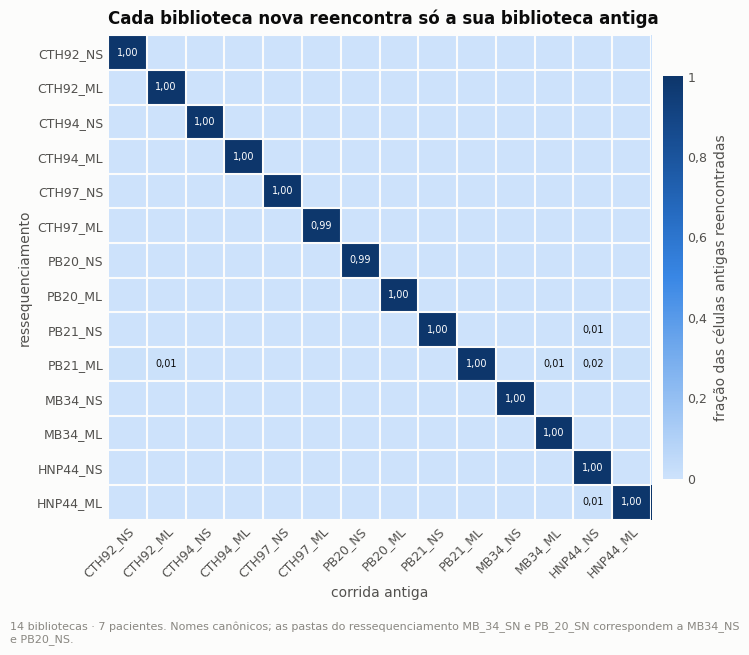

diagonal: 0,991 a 1,000 | maior valor fora da diagonal: 0,019


In [5]:
ov = compare.barcode_overlap(bc_old, bc_new)
diag = pd.Series(np.diag(ov.to_numpy()), index=LIBS)
fora = ov.to_numpy()[~np.eye(len(LIBS), dtype=bool)]
assert diag.min() > 0.98 and fora.max() < 0.05, "identidade de biblioteca não confirmada"

fig, ax = plt.subplots(figsize=(7.4, 6.2))
plotting.heatmap(ax, ov, fmt=".2f", annotate_above=0.005, vmin=0, vmax=1,
                 cbar_label="fração das células antigas reencontradas", fontsize=7)
ax.set_xlabel("corrida antiga")
ax.set_ylabel("ressequenciamento")
ax.set_title("Cada biblioteca nova reencontra só a sua biblioteca antiga")
fig.tight_layout()
plotting.note(fig, f"{plotting.N_DESIGN}. Nomes canônicos; as pastas do ressequenciamento "
                   "MB_34_SN e PB_20_SN correspondem a MB34_NS e PB20_NS.")
plotting.savefig(fig, NB, "identidade_barcodes",
                 description="Sobreposição de barcodes de células entre corridas", data=ov)
plt.show()

print(f"diagonal: {F.f(diag.min(), 3)} a {F.f(diag.max(), 3)} | maior valor fora da diagonal: "
      f"{F.f(fora.max(), 3)}")

In [6]:
sexo = lib[["XIST_antiga", "Y_antiga", "XIST_nova", "Y_nova"]].copy()
sexo["sexo_inferido"] = np.where(sexo["XIST_nova"] > 0.2, "feminino",
                                 np.where(sexo["Y_nova"] > 0.5, "masculino", "indefinido"))
sexo.insert(0, "paciente", [config.patient_of(l) for l in sexo.index])
pares_ok = sexo.groupby("paciente")["sexo_inferido"].nunique().eq(1).all()
assert pares_ok and (sexo["sexo_inferido"] != "indefinido").all()
assert sexo.groupby("paciente")["sexo_inferido"].first().to_dict() == config.PATIENT_SEX
print("sexo inferido por paciente:",
      sexo.groupby("paciente")["sexo_inferido"].first().reindex(config.PATIENTS).to_dict())
F.styler(sexo, {c: F.pct for c in ["XIST_antiga", "Y_antiga", "XIST_nova", "Y_nova"]})

sexo inferido por paciente: {'CTH92': 'feminino', 'CTH94': 'feminino', 'CTH97': 'masculino', 'PB20': 'feminino', 'PB21': 'feminino', 'MB34': 'masculino', 'HNP44': 'feminino'}


,paciente,XIST_antiga,Y_antiga,XIST_nova,Y_nova,sexo_inferido
library_id,,,,,,
CTH92_NS,CTH92,"63,0%","0,5%","64,6%","0,7%",feminino
CTH92_ML,CTH92,"46,2%","0,3%","48,2%","0,7%",feminino
CTH94_NS,CTH94,"71,4%","0,1%","78,9%","0,6%",feminino
CTH94_ML,CTH94,"67,4%","0,9%","68,6%","1,3%",feminino
CTH97_NS,CTH97,"0,1%","93,8%","0,0%","93,3%",masculino
CTH97_ML,CTH97,"0,0%","73,7%","0,0%","74,9%",masculino
PB20_NS,PB20,"43,5%","0,8%","44,7%","1,1%",feminino
PB20_ML,PB20,"48,7%","0,5%","50,9%","1,0%",feminino
PB21_NS,PB21,"46,5%","0,2%","47,8%","0,3%",feminino


A identidade está confirmada duas vezes: pelos barcodes (diagonal ~1, resto
~0, sem troca de amostra, inclusive nas duas bibliotecas de sufixo `SN`) e
pelo sexo do doador, que é o mesmo nas duas condições de cada paciente e nas
duas corridas. CTH97 e MB34 são homens; os demais, mulheres. Esse detalhe
volta em A02: XIST é um dos genes que o `inner join` descarta.

In [7]:
log.add("INFO", "identidade das bibliotecas",
        "[verificado] as 14 bibliotecas ressequenciadas são as mesmas da corrida antiga, sem troca de amostra",
        evidence=f"sobreposição de barcodes de {F.f(diag.min(), 3)} a {F.f(diag.max(), 3)} na "
                 f"diagonal e no máximo {F.f(fora.max(), 3)} fora dela; sexo do doador "
                 "consistente entre condições e entre corridas nos 7 pacientes",
        impact="permite parear células entre corridas; confirma MB_34_SN ≡ MB34_NS e "
               "PB_20_SN ≡ PB20_NS",
        recommendation="nenhuma")

## 2. Chamada de células

In [8]:
chamada = lib[["celulas_antiga", "celulas_nova", "pareadas", "so_antiga", "so_nova"]].copy()
chamada["umis_medianos_so_nova"] = only_new.groupby("library_id")["umis_nova"].median()
chamada["umis_medianos_so_antiga"] = only_old.groupby("library_id")["umis_antiga"].median()
io.save_table(chamada, NB, "chamada_de_celulas",
              description="Células chamadas em cada corrida e barcodes exclusivos de uma delas")
F.styler(chamada, {c: F.n for c in chamada.columns})

,celulas_antiga,celulas_nova,pareadas,so_antiga,so_nova,umis_medianos_so_nova,umis_medianos_so_antiga
library_id,,,,,,,
CTH92_NS,847,851,846,1,5,521,3.128
CTH92_ML,1.562,1.570,1.562,0,8,530,–
CTH94_NS,5.981,6.090,5.972,9,118,664,2.438
CTH94_ML,546,547,546,0,1,543,–
CTH97_NS,1.603,1.628,1.603,0,25,566,–
CTH97_ML,4.695,4.737,4.654,41,83,538,1.211
PB20_NS,637,635,632,5,3,834,2.611
PB20_ML,838,841,837,1,4,2.354,540
PB21_NS,3.919,4.266,3.919,0,347,559,–


In [9]:
# Os barcodes que eram célula só na corrida antiga continuam existindo na matriz bruta nova?
linhas = []
for l in only_old["library_id"].unique():
    raw = io.read_raw(l)
    pos = {b: i for i, b in enumerate(raw["barcodes"])}
    sub = only_old[only_old["library_id"] == l]
    idx = np.array([pos.get(b, -1) for b in sub["barcode"]])
    tot, _ = compare.per_cell(raw["X"][idx[idx >= 0]])
    out = sub.copy()
    out["umis_nova_bruta"] = np.nan
    out.loc[out.index[idx >= 0], "umis_nova_bruta"] = tot
    linhas.append(out)
    del raw
so_antiga = pd.concat(linhas, ignore_index=True)
io.save_table(so_antiga, NB, "barcodes_so_antiga",
              description="Barcodes chamados como célula só na corrida antiga, com a contagem na "
                          "matriz bruta nova", index=False)

n_so_nova = len(only_new)
print(f"só na nova: {F.n(n_so_nova)} barcodes; UMIs na nova — mediana {F.n(only_new['umis_nova'].median())}, "
      f"quartis {F.n(only_new['umis_nova'].quantile(.25))}–{F.n(only_new['umis_nova'].quantile(.75))}; "
      f"{F.pct((only_new['umis_nova'] < 1000).mean(), 0)} com menos de 1.000 UMIs")
print(f"só na antiga: {F.n(len(so_antiga))} barcodes; UMIs na antiga — mediana "
      f"{F.n(so_antiga['umis_antiga'].median())}; na matriz bruta nova — mediana "
      f"{F.n(so_antiga['umis_nova_bruta'].median())}; "
      f"{F.pct((so_antiga['umis_nova_bruta'] >= 500).mean(), 0)} têm ≥ 500 UMIs na nova")
print(f"mediana de UMIs das células pareadas na nova: {F.n(cells['umis_nova'].median())}")

só na nova: 806 barcodes; UMIs na nova — mediana 569, quartis 526–665; 90% com menos de 1.000 UMIs
só na antiga: 69 barcodes; UMIs na antiga — mediana 1.585; na matriz bruta nova — mediana 1.657; 99% têm ≥ 500 UMIs na nova
mediana de UMIs das células pareadas na nova: 9.244


**Leitura.** A chamada de células é praticamente a mesma. Os barcodes que
passaram a ser célula só no ressequenciamento têm contagem logo acima de 500
UMIs — o piso do EmptyDrops —, muito abaixo da mediana das células pareadas:
são barcodes de baixo conteúdo que a profundidade extra empurrou para cima
do limiar, não células que estavam escondidas. O ressequenciamento **não
recuperou células**.

In [10]:
log.add("MAJOR", "chamada de células",
        "o ressequenciamento não recuperou células; as poucas adicionais são barcodes de baixo conteúdo",
        evidence=f"{F.n(lib['celulas_antiga'].sum())} → {F.n(lib['celulas_nova'].sum())} células "
                 f"({F.pct(lib['celulas_nova'].sum() / lib['celulas_antiga'].sum() - 1, 1, True)}); "
                 f"os {F.n(n_so_nova)} barcodes novos têm mediana de "
                 f"{F.n(only_new['umis_nova'].median())} UMIs contra "
                 f"{F.n(cells['umis_nova'].median())} das células pareadas; "
                 f"{only_new['library_id'].value_counts().idxmax()} concentra "
                 f"{F.n(only_new['library_id'].value_counts().max())} deles",
        impact="o número de células é fixado na captura; a profundidade só acrescenta "
               "barcodes na fronteira do limiar, que são candidatos a remoção no QC",
        recommendation="não esperar ganho de células com sequenciamento; avaliar esses "
                       "barcodes de baixa contagem em A02")

## 3. Ganho por célula pareada

A profundidade da corrida antiga não está registrada. Ela é estimada pela
curva de subamostragem do ressequenciamento (C01): a profundidade em que a
mediana de UMIs por célula iguala a mediana observada na corrida antiga. A
estimativa supõe que as duas corridas amostram a mesma biblioteca; C03
confere isso molécula a molécula.

In [11]:
ganho = cells.groupby("library_id").agg(
    pareadas=("barcode", "size"),
    umis_antiga=("umis_antiga", "median"), umis_nova=("umis_nova", "median"),
    genes_antiga=("genes_antiga", "median"), genes_nova=("genes_nova", "median"),
    razao_umis=("razao_umis", "median"), razao_genes=("razao_genes", "median"),
    soma_antiga=("umis_antiga", "sum"), soma_nova=("umis_nova", "sum"),
).reindex(LIBS)

curvas = {l: io.web_summary_curves(io.load_web_summary(l)) for l in LIBS}
metr = pd.DataFrame({l: io.read_metrics(l) for l in LIBS}).T
ganho["reads_por_celula_nova"] = metr["Mean Reads per Cell"]
ganho["reads_por_celula_antiga_est"] = [
    float(np.interp(lib.loc[l, "umis_medianos_antiga"], curvas[l]["median_umis"],
                    curvas[l]["mean_reads_per_cell"])) for l in LIBS]
ganho["x_profundidade"] = ganho["reads_por_celula_nova"] / ganho["reads_por_celula_antiga_est"]
ganho["reads_antiga_est"] = ganho["reads_por_celula_antiga_est"] * lib["celulas_antiga"]
ganho["saturacao_antiga_est"] = [
    float(np.interp(ganho.loc[l, "reads_por_celula_antiga_est"], curvas[l]["mean_reads_per_cell"],
                    curvas[l]["saturation"])) for l in LIBS]
ganho["saturacao_nova"] = metr["Sequencing Saturation"]
io.save_table(ganho, NB, "ganho_por_biblioteca",
              description="Ganho de UMIs e genes por célula pareada e profundidade antiga estimada")

F.styler(ganho[["pareadas", "umis_antiga", "umis_nova", "razao_umis", "genes_antiga", "genes_nova",
                "razao_genes", "reads_por_celula_antiga_est", "reads_por_celula_nova",
                "x_profundidade", "saturacao_antiga_est", "saturacao_nova"]],
         {"pareadas": F.n, "umis_antiga": F.n, "umis_nova": F.n, "razao_umis": F.x,
          "genes_antiga": F.n, "genes_nova": F.n, "razao_genes": F.x,
          "reads_por_celula_antiga_est": F.n, "reads_por_celula_nova": F.n,
          "x_profundidade": lambda v: F.x(v, 1), "saturacao_antiga_est": F.pct,
          "saturacao_nova": F.pct})

,pareadas,umis_antiga,umis_nova,razao_umis,genes_antiga,genes_nova,razao_genes,reads_por_celula_antiga_est,reads_por_celula_nova,x_profundidade,saturacao_antiga_est,saturacao_nova
library_id,,,,,,,,,,,,
CTH92_NS,846,9.328,9.896,"1,07×",2.974,3.124,"1,05×",535.278,1.970.584,"3,7×","95,3%","98,7%"
CTH92_ML,1.562,3.742,4.052,"1,09×",1.706,1.842,"1,08×",220.456,1.124.003,"5,1×","94,3%","98,8%"
CTH94_NS,5.972,8.036,11.914,"1,48×",2.873,3.680,"1,28×",41.993,443.895,"10,6×","65,3%","95,1%"
CTH94_ML,546,10.732,11.303,"1,05×",3.256,3.391,"1,04×",658.135,2.609.552,"4,0×","95,6%","98,9%"
CTH97_NS,1.603,7.963,8.644,"1,09×",2.685,2.913,"1,08×",279.936,1.293.457,"4,6×","93,2%","98,4%"
CTH97_ML,4.654,2.279,2.444,"1,07×",949,1.022,"1,07×",122.835,380.618,"3,1×","96,0%","98,6%"
PB20_NS,632,8.826,9.243,"1,05×",2.536,2.647,"1,05×",708.625,2.790.817,"3,9×","96,9%","99,2%"
PB20_ML,837,9.904,10.226,"1,04×",2.785,2.892,"1,04×",777.860,1.944.651,"2,5×","97,3%","98,9%"
PB21_NS,3.919,8.131,9.632,"1,18×",2.537,2.890,"1,14×",104.079,360.107,"3,5×","83,2%","94,2%"


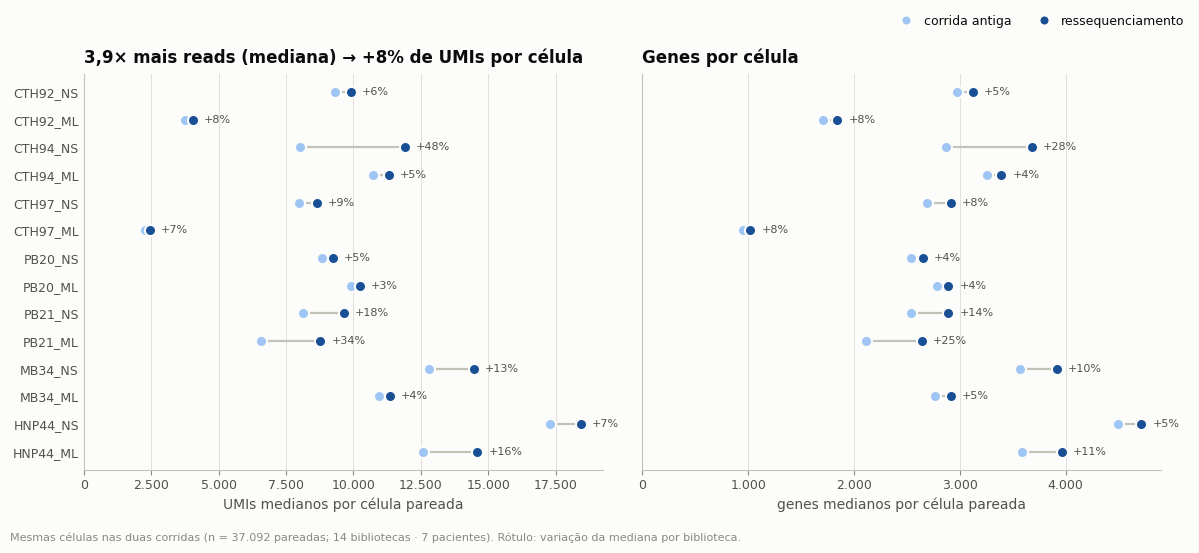

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
plotting.dumbbell(axes[0], ganho["umis_antiga"], ganho["umis_nova"], labels=LIBS,
                  xlabel="UMIs medianos por célula pareada", legend=False,
                  value_fmt=lambda b, a: F.pct(a / b - 1, 0, True))
plotting.dumbbell(axes[1], ganho["genes_antiga"], ganho["genes_nova"], labels=LIBS,
                  xlabel="genes medianos por célula pareada", legend=False,
                  value_fmt=lambda b, a: F.pct(a / b - 1, 0, True))
for ax in axes:
    plotting.thousands(ax, "x")
    ax.set_xlim(0, None)
med_x = ganho["x_profundidade"].median()
med_g = ganho["razao_umis"].median()
axes[0].set_title(f"{F.x(med_x, 1)} mais reads (mediana) → {F.pct(med_g - 1, 0, True)} de UMIs por célula")
axes[1].set_title("Genes por célula")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(handles=plotting.old_new_handles(), loc="upper right", ncol=2,
           bbox_to_anchor=(0.995, 1.0))
plotting.note(fig, f"Mesmas células nas duas corridas (n = {F.n(n_pares)} pareadas; {plotting.N_DESIGN}). "
                   "Rótulo: variação da mediana por biblioteca.")
plotting.savefig(fig, NB, "ganho_por_celula",
                 description="UMIs e genes medianos por célula pareada, corrida antiga → ressequenciamento",
                 data=ganho[["umis_antiga", "umis_nova", "genes_antiga", "genes_nova"]])
plt.show()

In [13]:
pouco = ganho.index[ganho["razao_umis"] < 1.10].tolist()
muito = ganho.sort_values("razao_umis", ascending=False).head(2)
print(f"profundidade antiga estimada: {F.n(ganho['reads_por_celula_antiga_est'].min())} a "
      f"{F.n(ganho['reads_por_celula_antiga_est'].max())} reads/célula "
      f"(≈ {F.compact(ganho['reads_antiga_est'].min())} a {F.compact(ganho['reads_antiga_est'].max())} "
      f"de reads por biblioteca); saturação estimada {F.pct(ganho['saturacao_antiga_est'].min(), 0)} a "
      f"{F.pct(ganho['saturacao_antiga_est'].max(), 0)}")
print(f"aumento de profundidade: {F.x(ganho['x_profundidade'].min(), 1)} a "
      f"{F.x(ganho['x_profundidade'].max(), 1)} (mediana {F.x(med_x, 1)})")
print(f"ganho de UMIs por célula (mediana por biblioteca): {F.pct(ganho['razao_umis'].min() - 1, 0, True)} a "
      f"{F.pct(ganho['razao_umis'].max() - 1, 0, True)}; abaixo de +10% em {len(pouco)} de 14 bibliotecas")
print(f"maiores ganhos: " + "; ".join(
    f"{l} {F.pct(r['razao_umis'] - 1, 0, True)} (saturação antiga est. {F.pct(r['saturacao_antiga_est'], 0)})"
    for l, r in muito.iterrows()))
rho = stats.spearmanr(ganho["saturacao_antiga_est"], ganho["razao_umis"]).statistic
print(f"Spearman saturação antiga estimada × ganho de UMIs (n=14, descritivo): {F.f(rho, 2)}")

profundidade antiga estimada: 36.273 a 5.218.792 reads/célula (≈ 251,2 mi a 681,0 mi de reads por biblioteca); saturação estimada 65% a 99%
aumento de profundidade: 2,4× a 10,6× (mediana 3,9×)
ganho de UMIs por célula (mediana por biblioteca): +4% a +48%; abaixo de +10% em 9 de 14 bibliotecas
maiores ganhos: CTH94_NS +48% (saturação antiga est. 65%); PB21_ML +34% (saturação antiga est. 67%)
Spearman saturação antiga estimada × ganho de UMIs (n=14, descritivo): -0,94


**Leitura.** O ressequenciamento multiplicou a profundidade várias vezes e o
ganho por célula ficou abaixo de 10% na maioria das bibliotecas. As duas que
mais ganharam são justamente as que estavam menos saturadas na corrida
antiga — as que tinham mais células para a mesma quantidade de reads. É o
comportamento esperado de uma biblioteca finita: quem já estava perto do
teto quase não sobe.

In [14]:
log.add("CRITICAL", "ganho do ressequenciamento",
        "a profundidade adicional rendeu poucos UMIs por célula",
        evidence=f"aumento de profundidade de {F.x(ganho['x_profundidade'].min(), 1)} a "
                 f"{F.x(ganho['x_profundidade'].max(), 1)} (mediana {F.x(med_x, 1)}); ganho mediano de "
                 f"UMIs por célula pareada de {F.pct(ganho['razao_umis'].min() - 1, 0, True)} a "
                 f"{F.pct(ganho['razao_umis'].max() - 1, 0, True)}, abaixo de +10% em "
                 f"{len(pouco)}/14 bibliotecas; genes por célula "
                 f"{F.pct(ganho['razao_genes'].min() - 1, 0, True)} a "
                 f"{F.pct(ganho['razao_genes'].max() - 1, 0, True)}",
        impact="a corrida antiga já estava, segundo a estimativa, entre "
               f"{F.pct(ganho['saturacao_antiga_est'].min(), 0)} e "
               f"{F.pct(ganho['saturacao_antiga_est'].max(), 0)} de saturação; o objeto novo tem "
               "essencialmente a mesma informação por célula",
        recommendation="tratar o ressequenciamento como réplica técnica de leitura, não como "
                       "ganho de sensibilidade; não repetir a estratégia")

## 4. As contagens se reproduzem entre corridas?

Se a corrida nova é uma leitura mais profunda da mesma biblioteca, uma
molécula contada na antiga deveria reaparecer. O teste mais limpo são as
entradas (célula, gene) com exatamente 1 UMI na corrida antiga: ou a molécula
reaparece, ou a entrada zera.

In [15]:
rep = lib[["unicas_1umi_antiga", "unicas_1umi_zeraram", "frac_entradas_que_cairam",
           "frac_umis_perdidos"]].copy()
rep["frac_1umi_nao_reproduzida"] = rep["unicas_1umi_zeraram"] / rep["unicas_1umi_antiga"]
io.save_table(rep, NB, "reprodutibilidade_das_contagens",
              description="Entradas (célula, gene) da corrida antiga que não se reproduzem na nova")
tot_1 = rep["unicas_1umi_antiga"].sum()
frac_nr = rep["unicas_1umi_zeraram"].sum() / tot_1
print(f"entradas com 1 UMI na corrida antiga: {F.n(tot_1)}; não reproduzidas na nova: "
      f"{F.pct(frac_nr)} (por biblioteca: {F.pct(rep['frac_1umi_nao_reproduzida'].min())} a "
      f"{F.pct(rep['frac_1umi_nao_reproduzida'].max())})")
F.styler(rep, {"unicas_1umi_antiga": F.n, "unicas_1umi_zeraram": F.n,
               "frac_entradas_que_cairam": F.pct, "frac_umis_perdidos": F.pct,
               "frac_1umi_nao_reproduzida": F.pct})

entradas com 1 UMI na corrida antiga: 54.012.253; não reproduzidas na nova: 5,4% (por biblioteca: 3,0% a 8,0%)


,unicas_1umi_antiga,unicas_1umi_zeraram,frac_entradas_que_cairam,frac_umis_perdidos,frac_1umi_nao_reproduzida
library_id,,,,,
CTH92_NS,1.383.492,42.319,"4,8%","1,5%","3,1%"
CTH92_ML,1.920.659,57.939,"4,5%","1,7%","3,0%"
CTH94_NS,9.929.291,454.678,"4,6%","1,6%","4,6%"
CTH94_ML,943.586,29.279,"5,3%","1,7%","3,1%"
CTH97_NS,2.565.453,84.508,"4,6%","1,6%","3,3%"
CTH97_ML,3.566.849,155.521,"5,8%","2,1%","4,4%"
PB20_NS,948.015,31.454,"5,2%","1,6%","3,3%"
PB20_ML,1.337.978,46.794,"6,1%","1,9%","3,5%"
PB21_NS,6.205.618,498.042,"8,4%","2,8%","8,0%"


In [16]:
genes = pd.DataFrame({
    "gene": names, "gene_id": features["gene_id"].to_numpy(),
    "pos_antiga": G["pos_old"].sum(0), "pos_nova": G["pos_new"].sum(0),
    "umis_antiga": G["umi_old"].sum(0), "umis_nova": G["umi_new"].sum(0),
    "umis_perdidos": G["lost"].sum(0),
}).set_index("gene")
genes["razao_umis"] = genes["umis_nova"] / genes["umis_antiga"].replace(0, np.nan)
genes["razao_pos"] = genes["pos_nova"] / genes["pos_antiga"].replace(0, np.nan)
genes["umis_por_cel_pos_antiga"] = genes["umis_antiga"] / genes["pos_antiga"].replace(0, np.nan)
genes["umis_por_cel_pos_nova"] = genes["umis_nova"] / genes["pos_nova"].replace(0, np.nan)
io.save_data(genes.reset_index(), NB, "genes_antigo_novo",
             description="Totais por gene nas células pareadas: células positivas e UMIs, antiga e nova")

expr = genes[genes["umis_antiga"] >= 200]
colapso = expr[expr["razao_umis"] < 0.5].sort_values("umis_antiga", ascending=False)
print(f"genes com ≥ 200 UMIs na corrida antiga: {F.n(len(expr))}; razão nova/antiga — mediana "
      f"{F.x(expr['razao_umis'].median())}, percentis 5–95: {F.x(expr['razao_umis'].quantile(.05))} a "
      f"{F.x(expr['razao_umis'].quantile(.95))}")
print(f"genes que perderam mais da metade dos UMIs: {F.n(len(colapso))} "
      f"({F.pct(len(colapso) / len(expr))} dos genes; "
      f"{F.pct(colapso['umis_antiga'].sum() / genes['umis_antiga'].sum(), 2)} dos UMIs da corrida antiga)")

# onde esses genes estavam na corrida antiga
ci = [int(np.flatnonzero(names == g)[0]) for g in colapso.index]
por_lib = pd.DataFrame(G["umi_old"][:, ci], index=LIBS, columns=colapso.index)
conc = (por_lib.sum(1) / por_lib.sum().sum()).sort_values(ascending=False)
print("\nparcela dos UMIs antigos desses genes por biblioteca: " +
      "; ".join(f"{l} {F.pct(v, 0)}" for l, v in conc.head(4).items()))
top = colapso.head(12)[["umis_antiga", "umis_nova", "pos_antiga", "pos_nova", "razao_umis"]]
F.styler(top, {"umis_antiga": F.n, "umis_nova": F.n, "pos_antiga": F.n, "pos_nova": F.n,
               "razao_umis": F.x})

[io] inalterado, não regravado: genes_antigo_novo.parquet
genes com ≥ 200 UMIs na corrida antiga: 16.747; razão nova/antiga — mediana 1,31×, percentis 5–95: 1,17× a 1,58×
genes que perderam mais da metade dos UMIs: 85 (0,5% dos genes; 0,04% dos UMIs da corrida antiga)

parcela dos UMIs antigos desses genes por biblioteca: PB21_NS 59%; PB21_ML 12%; CTH97_ML 10%; MB34_NS 6%


,umis_antiga,umis_nova,pos_antiga,pos_nova,razao_umis
gene,,,,,
ZFPM2,11.803,3.536,6.562,2.740,"0,30×"
ENSG00000222031,7.742,259,5.000,256,"0,03×"
ENSG00000290778,7.232,332,4.682,322,"0,05×"
ENSG00000233290,6.960,553,4.604,490,"0,08×"
TLE1-DT,6.465,1.051,4.425,797,"0,16×"
TOX2,4.448,1.803,3.219,1.058,"0,41×"
SEMA3E,4.097,1.447,3.127,1.312,"0,35×"
LIMCH1,3.436,544,2.667,388,"0,16×"
LINC00558,2.925,192,2.345,190,"0,07×"


In [17]:
io.save_table(colapso, NB, "genes_que_colapsaram",
              description="Genes com ≥200 UMIs na corrida antiga que perderam mais da metade no ressequenciamento")

# os HVGs da análise antiga incluíam esses genes?
import h5py
with h5py.File(config.OLD_HARMONY, "r") as f:
    hv = io._dec(f["var/gene_ids"][()])
hvg_antigos = set(hv)
col_ids = set(colapso["gene_id"])
n_hvg_col = len(hvg_antigos & col_ids)
hvg_col = colapso[colapso["gene_id"].isin(hvg_antigos)].index.tolist()
print(f"dos {F.n(len(hvg_antigos))} HVGs do objeto antigo (adata_harmony.h5ad), {n_hvg_col} estão "
      f"entre os {len(colapso)} genes que colapsaram: {hvg_col}")

# alguns desses genes por biblioteca: células positivas, antiga → nova
exemplos = [g for g in ["ZFPM2", "ENSG00000222031", "TOX2", "DSCAM"] if g in colapso.index]
ei = [int(np.flatnonzero(names == g)[0]) for g in exemplos]
ex = pd.DataFrame({g: [f"{F.n(a)} → {F.n(b)}" for a, b in zip(G["pos_old"][:, j], G["pos_new"][:, j])]
                   for g, j in zip(exemplos, ei)}, index=LIBS)
ex.insert(0, "células", [F.n(v) for v in ganho["pareadas"]])
ex

dos 2.000 HVGs do objeto antigo (adata_harmony.h5ad), 3 estão entre os 85 genes que colapsaram: ['TOX2', 'LIMCH1', 'DAPK1']


,células,ZFPM2,ENSG00000222031,TOX2,DSCAM
CTH92_NS,846,35 → 45,16 → 0,24 → 22,22 → 17
CTH92_ML,1.562,73 → 49,54 → 0,58 → 44,25 → 28
CTH94_NS,5.972,131 → 220,40 → 10,117 → 141,59 → 102
CTH94_ML,546,40 → 17,8 → 0,23 → 23,8 → 11
CTH97_NS,1.603,263 → 257,170 → 23,93 → 49,63 → 72
CTH97_ML,4.654,1.082 → 222,774 → 27,336 → 34,247 → 68
PB20_NS,632,77 → 26,61 → 1,59 → 28,27 → 9
PB20_ML,837,73 → 28,35 → 0,33 → 22,17 → 11
PB21_NS,3.919,2.785 → 1.274,2.307 → 150,1.511 → 207,1.186 → 367
PB21_ML,11.240,1.142 → 205,922 → 17,505 → 199,329 → 67


**Leitura.** Duas coisas diferentes aparecem aqui.

*Detecções de 1 UMI que não se reproduzem.* Alguns por cento das detecções
de 1 UMI da corrida antiga não reaparecem numa leitura várias vezes mais
profunda. Há duas explicações, e os dados disponíveis não as separam (a
corrida antiga não tem `molecule_info` nem versão do pipeline registrada):

* eram moléculas espúrias de baixo suporte de reads — a classe que C03 mede
  diretamente no ressequenciamento; ou
* as bibliotecas ressequenciadas foram **preparadas de novo** a partir do
  mesmo cDNA, e parte das moléculas da preparação antiga não foi amostrada
  outra vez. Só o registro de bancada distingue isso de um simples
  recarregamento da mesma biblioteca.

Para a análise, a consequência é a mesma: uma detecção isolada de 1 UMI tem
alguns por cento de chance de não se confirmar.

*Genes que colapsaram.* Um conjunto pequeno de genes tinha milhares de UMIs
na corrida antiga e quase nenhum na nova. Mais reads não tiram moléculas, e o
efeito é específico de genes e de bibliotecas (mais da metade em PB21_NS). A
lista é dominada por genes longos sem papel conhecido em T CD4⁺, com ~1 UMI
por célula em milhares de células. Em C03, o que resta deles no
ressequenciamento é quase todo intrônico e sustentado por 1–2 reads. O
padrão é de leitura espúria, não de expressão; o mecanismo não é
determinável sem os alinhamentos da corrida antiga. O peso no conjunto é
pequeno, mas a lista inclui **TOX2**, que costuma entrar em assinaturas de
TFH: na corrida antiga, a maior parte das células "TOX2⁺" não se sustenta.

In [18]:
log.add("MINOR", "corrida antiga — genes com contagem que não se reproduz",
        "um conjunto pequeno de genes tinha milhares de UMIs na corrida antiga e quase desaparece no ressequenciamento",
        evidence=f"{F.n(len(colapso))} genes com ≥ 200 UMIs perderam mais da metade (ex.: "
                 + ", ".join(f"{g} {F.n(r['umis_antiga'])}→{F.n(r['umis_nova'])}"
                             for g, r in colapso.head(4).iterrows())
                 + f"); somavam {F.pct(colapso['umis_antiga'].sum() / genes['umis_antiga'].sum(), 2)} "
                   f"dos UMIs antigos, {F.pct(conc.iloc[0], 0)} deles em {conc.index[0]}; "
                   f"{n_hvg_col} dos {F.n(len(hvg_antigos))} HVGs antigos estão na lista ({', '.join(hvg_col)}); "
                   f"TOX2: {F.n(colapso.loc['TOX2', 'pos_antiga'])} → {F.n(colapso.loc['TOX2', 'pos_nova'])} células positivas",
        impact="efeito desprezível sobre o clustering antigo, mas relevante para quem usou "
               "esses genes como marcador: TOX2 entra em assinaturas de TFH, e a maioria das "
               "células TOX2⁺ da corrida antiga não se confirma",
        recommendation="conferir marcadores e assinaturas contra "
                       "tables/C02_antigo_vs_novo/genes_que_colapsaram.csv antes de reaproveitar "
                       "resultados da corrida antiga")
log.add("MINOR", "reprodutibilidade de detecções de 1 UMI",
        "parte das detecções de 1 UMI da corrida antiga não reaparece na leitura mais profunda",
        evidence=f"{F.pct(frac_nr)} de {F.n(tot_1)} entradas (célula, gene) com 1 UMI na antiga "
                 f"zeram na nova (de {F.pct(rep['frac_1umi_nao_reproduzida'].min())} a "
                 f"{F.pct(rep['frac_1umi_nao_reproduzida'].max())} por biblioteca)",
        impact="detecções de 1 UMI — a situação das citocinas de baixa expressão — têm alguns % "
               "de chance de não se confirmar, por molécula espúria ou por reamostragem da "
               "biblioteca",
        recommendation="não interpretar célula isolada com 1 UMI como positiva; usar fração de "
                       "positivas por grupo; ver o suporte de reads por molécula em C03. "
                       "Confirmar na bancada se o ressequenciamento usou as mesmas bibliotecas "
                       "finais ou uma nova preparação a partir do cDNA")

## 5. Quem ganhou com a profundidade

Para cada gene, a razão entre células positivas na nova e na antiga, em
função de quantos UMIs o gene tem por célula positiva. Genes no limite de
detecção (≈1 UMI por célula positiva) são os que mais poderiam ganhar.

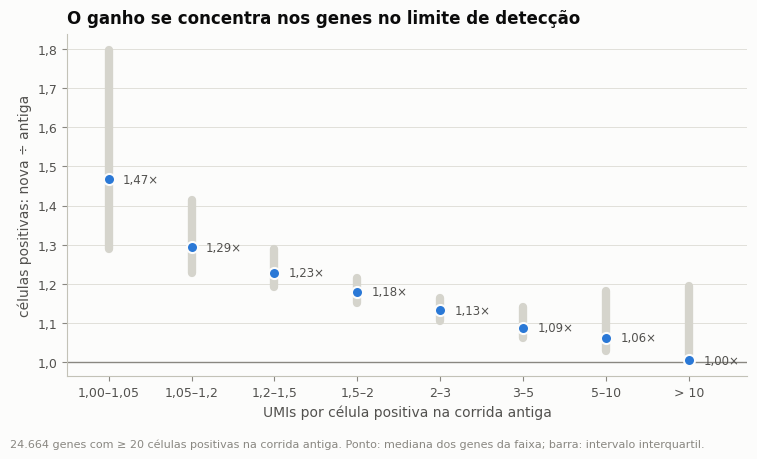

In [19]:
base = genes[(genes["pos_antiga"] >= 20) & ~genes.index.isin(colapso.index)].copy()
bins = [1, 1.05, 1.2, 1.5, 2, 3, 5, 10, np.inf]
rot = ["1,00–1,05", "1,05–1,2", "1,2–1,5", "1,5–2", "2–3", "3–5", "5–10", "> 10"]
base["faixa"] = pd.cut(base["umis_por_cel_pos_antiga"], bins, labels=rot, right=False)
faixas = base.groupby("faixa", observed=True)["razao_pos"].agg(
    n_genes="size", mediana="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
io.save_table(faixas, NB, "ganho_por_nivel_de_expressao",
              description="Razão de células positivas (nova/antiga) por faixa de UMIs por célula positiva")

fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(faixas))
ax.vlines(x, faixas["q25"], faixas["q75"], color=plotting.CONTEXT, lw=6, zorder=2,
          capstyle="round")
ax.plot(x, faixas["mediana"], "o", ms=8, mfc=plotting.ACCENT, mec=INK["surface"], mew=1.5, zorder=3)
for xi, v in zip(x, faixas["mediana"]):
    ax.annotate(F.x(v), (xi, v), textcoords="offset points", xytext=(10, 0), va="center",
                fontsize=8.5, color=INK["secondary"])
ax.axhline(1, color=INK["muted"], lw=1, zorder=1)
ax.set_xticks(x)
ax.set_xticklabels(faixas.index)
ax.set_xlim(-0.5, len(faixas) - 0.3)
ax.set_xlabel("UMIs por célula positiva na corrida antiga")
ax.set_ylabel("células positivas: nova ÷ antiga")
plotting.decimals(ax, "y", 1)
ax.set_title("O ganho se concentra nos genes no limite de detecção")
fig.tight_layout()
plotting.note(fig, f"{F.n(len(base))} genes com ≥ 20 células positivas na corrida antiga. "
                   "Ponto: mediana dos genes da faixa; barra: intervalo interquartil.")
plotting.savefig(fig, NB, "ganho_por_nivel_de_expressao",
                 description="Ganho de células positivas por gene em função do nível de expressão",
                 data=faixas)
plt.show()

Genes com muitos UMIs por célula positiva não ganham nada: quem expressa já
era detectado. Genes com ~1 UMI por célula positiva ganham dezenas de
pontos percentuais em células positivas — são eventos de 1 molécula, a
classe em que entram tanto moléculas reais pouco amplificadas quanto as
espúrias de baixo suporte da seção anterior. C03 separa as duas.

## 6. Citocinas

In [20]:
cit = genes.loc[PANEL, ["pos_antiga", "pos_nova", "umis_antiga", "umis_nova",
                        "umis_por_cel_pos_nova"]].copy()
cit["pct_antiga"] = cit["pos_antiga"] / n_pares
cit["pct_nova"] = cit["pos_nova"] / n_pares
cit["razao_pos"] = cit["pos_nova"] / cit["pos_antiga"].replace(0, np.nan)

pg = panel.assign(ganhou=(panel["antiga"] == 0) & (panel["nova"] > 0),
                  perdeu=(panel["antiga"] > 0) & (panel["nova"] == 0),
                  manteve=(panel["antiga"] > 0) & (panel["nova"] > 0),
                  ganhou_1umi=(panel["antiga"] == 0) & (panel["nova"] == 1))
mov = pg.groupby("gene")[["manteve", "ganhou", "perdeu", "ganhou_1umi"]].sum().reindex(PANEL).fillna(0).astype(int)
cit = cit.join(mov)
cit["classe"] = np.where(cit.index.isin(config.CYTOKINES), "citocina", "fator de transcrição")
io.save_table(cit, NB, "citocinas_antigo_novo",
              description="Citocinas e fatores de transcrição: células positivas e UMIs nas células pareadas")
F.styler(cit[["pos_antiga", "pos_nova", "razao_pos", "pct_antiga", "pct_nova", "umis_antiga",
              "umis_nova", "umis_por_cel_pos_nova", "manteve", "ganhou", "perdeu", "ganhou_1umi"]],
         {"pos_antiga": F.n, "pos_nova": F.n, "razao_pos": F.x, "pct_antiga": lambda v: F.pct(v, 2),
          "pct_nova": lambda v: F.pct(v, 2), "umis_antiga": F.n, "umis_nova": F.n,
          "umis_por_cel_pos_nova": lambda v: F.f(v, 1), "manteve": F.n, "ganhou": F.n,
          "perdeu": F.n, "ganhou_1umi": F.n})

,pos_antiga,pos_nova,razao_pos,pct_antiga,pct_nova,umis_antiga,umis_nova,umis_por_cel_pos_nova,manteve,ganhou,perdeu,ganhou_1umi
gene,,,,,,,,,,,,
IFNG,977,1.121,"1,15×","2,63%","3,02%",15.396,17.048,"15,2",919,202,58,195
TNF,1.973,2.381,"1,21×","5,32%","6,42%",3.346,4.169,"1,8",1.872,509,101,477
IL2,77,100,"1,30×","0,21%","0,27%",2.449,3.116,"31,2",67,33,10,32
IL4,82,105,"1,28×","0,22%","0,28%",94,120,"1,1",78,27,4,27
IL5,211,324,"1,54×","0,57%","0,87%",312,455,"1,4",203,121,8,113
IL9,115,142,"1,23×","0,31%","0,38%",2.152,2.300,"16,2",108,34,7,34
IL10,50,60,"1,20×","0,13%","0,16%",70,84,"1,4",45,15,5,15
IL13,56,69,"1,23×","0,15%","0,19%",253,282,"4,1",55,14,1,14
IL17A,75,80,"1,07×","0,20%","0,22%",674,740,"9,2",72,8,3,8


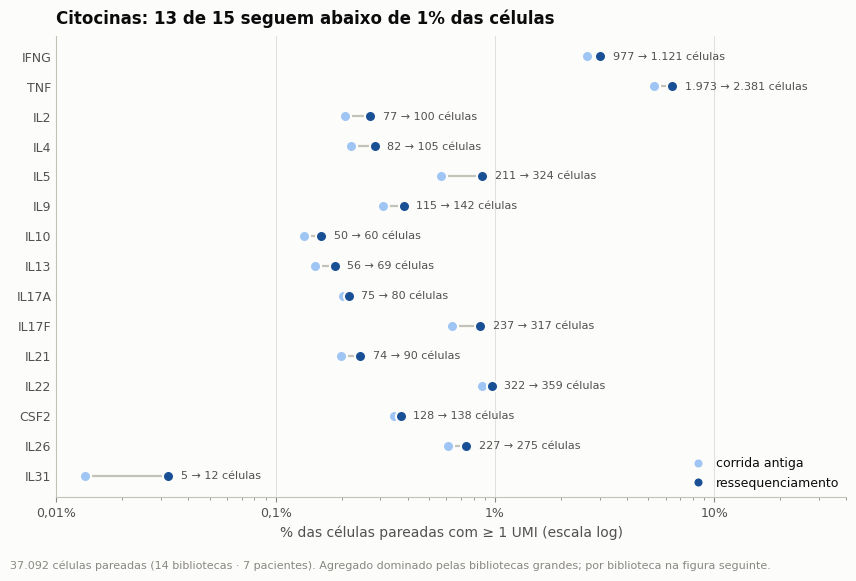

In [21]:
mostrar = [g for g in config.CYTOKINES if cit.loc[g, "pos_nova"] >= 10]
fig, ax = plt.subplots(figsize=(8.6, 5.6))
plotting.dumbbell(ax, cit.loc[mostrar, "pct_antiga"] * 100, cit.loc[mostrar, "pct_nova"] * 100,
                  labels=mostrar, log=True, xlabel="% das células pareadas com ≥ 1 UMI (escala log)",
                  value_fmt=lambda b, a: "")
for yi, g in zip(np.arange(len(mostrar))[::-1], mostrar):
    ax.annotate(f"{F.n(cit.loc[g, 'pos_antiga'])} → {F.n(cit.loc[g, 'pos_nova'])} células",
                (cit.loc[g, "pct_nova"] * 100, yi), textcoords="offset points", xytext=(9, 0),
                va="center", fontsize=8, color=INK["secondary"])
ax.set_xlim(0.01, 40)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 2 if v < 0.1 else 1 if v < 1 else 0) + "%"))
n_abaixo = int((cit.loc[mostrar, "pct_nova"] < 0.01).sum())
ax.set_title(f"Citocinas: {n_abaixo} de {len(mostrar)} seguem abaixo de 1% das células")
fig.tight_layout()
plotting.note(fig, f"{F.n(n_pares)} células pareadas ({plotting.N_DESIGN}). Agregado dominado pelas "
                   "bibliotecas grandes; por biblioteca na figura seguinte.")
plotting.savefig(fig, NB, "citocinas_antigo_novo",
                 description="Fração de células positivas por citocina, corrida antiga → ressequenciamento",
                 data=cit.loc[mostrar, ["pos_antiga", "pos_nova", "pct_antiga", "pct_nova"]])
plt.show()

In [22]:
alta = cit[(cit["classe"] == "citocina") & (cit["umis_por_cel_pos_nova"] >= 5)].index.tolist()
baixa = cit[(cit["classe"] == "citocina") & (cit["umis_por_cel_pos_nova"] < 2) & (cit["pos_nova"] >= 10)].index.tolist()
print("citocinas com muitos UMIs por célula positiva (≥ 5): " +
      "; ".join(f"{g} {F.f(cit.loc[g, 'umis_por_cel_pos_nova'], 1)}" for g in alta))
print("citocinas no limite de detecção (< 2 UMIs por célula positiva): " +
      "; ".join(f"{g} {F.f(cit.loc[g, 'umis_por_cel_pos_nova'], 1)}" for g in baixa))
soma = cit.loc[config.CYTOKINES, ["manteve", "ganhou", "perdeu", "ganhou_1umi"]].sum()
print(f"\nnas 16 citocinas: {F.n(soma['manteve'])} células-gene positivas nas duas corridas; "
      f"{F.n(soma['ganhou'])} ganharam positividade, das quais {F.pct(soma['ganhou_1umi'] / soma['ganhou'], 0)} "
      f"com exatamente 1 UMI; {F.n(soma['perdeu'])} eram positivas na antiga e zeraram na nova")
print(f"faixa da razão de células positivas nas citocinas com ≥ 50 positivas: "
      f"{F.x(cit[(cit['classe'] == 'citocina') & (cit['pos_antiga'] >= 50)]['razao_pos'].min())} a "
      f"{F.x(cit[(cit['classe'] == 'citocina') & (cit['pos_antiga'] >= 50)]['razao_pos'].max())}; "
      f"fatores de transcrição: {F.x(cit[cit['classe'] != 'citocina']['razao_pos'].min())} a "
      f"{F.x(cit[cit['classe'] != 'citocina']['razao_pos'].max())}")

citocinas com muitos UMIs por célula positiva (≥ 5): IFNG 15,2; IL2 31,2; IL9 16,2; IL17A 9,2; IL17F 26,7; IL22 12,9; CSF2 6,6
citocinas no limite de detecção (< 2 UMIs por célula positiva): TNF 1,8; IL4 1,1; IL5 1,4; IL10 1,4; IL26 1,5; IL31 1,0

nas 16 citocinas: 4.352 células-gene positivas nas duas corridas; 1.222 ganharam positividade, das quais 95% com exatamente 1 UMI; 259 eram positivas na antiga e zeraram na nova
faixa da razão de células positivas nas citocinas com ≥ 50 positivas: 1,07× a 1,54×; fatores de transcrição: 1,12× a 1,27×


**Leitura.** As citocinas se dividem em dois regimes, e nenhum deles se
resolve com profundidade:

* **Poucas células, muita expressão** (IFNG, IL2, IL9, IL17A, IL17F, IL22,
  CSF2; IL13 e IL21 ficam no meio, com ~4 UMIs): cada célula positiva tem
  vários a dezenas de UMIs. A detecção não está no limite — quem expressa já
  era visto na corrida antiga. A fração baixa é a frequência de células
  produtoras nesta preparação.
* **No limite de detecção** (IL4, IL5, IL10, IL26, TNF): 1 a 2 UMIs por
  célula positiva. São as que mais "ganham" células positivas, quase sempre
  com exatamente 1 UMI — a classe de evento que, na seção 4, deixa de se
  reproduzir numa fração dos casos. E há células que eram positivas na
  corrida antiga e zeram na nova.

Mesmo nas citocinas de alta expressão, quase todo o ganho é de células com
1 UMI. Numa biblioteca em que algumas células têm dezenas de UMIs de IFNG,
uma célula com 1 UMI é candidata a RNA ambiente, não a produtora; A02 mede
isso.

O ganho das citocinas não é maior que o dos fatores de transcrição nem que o
dos genes em geral com o mesmo nível de expressão (seção 5): não há efeito
específico sobre o que motivou o ressequenciamento.

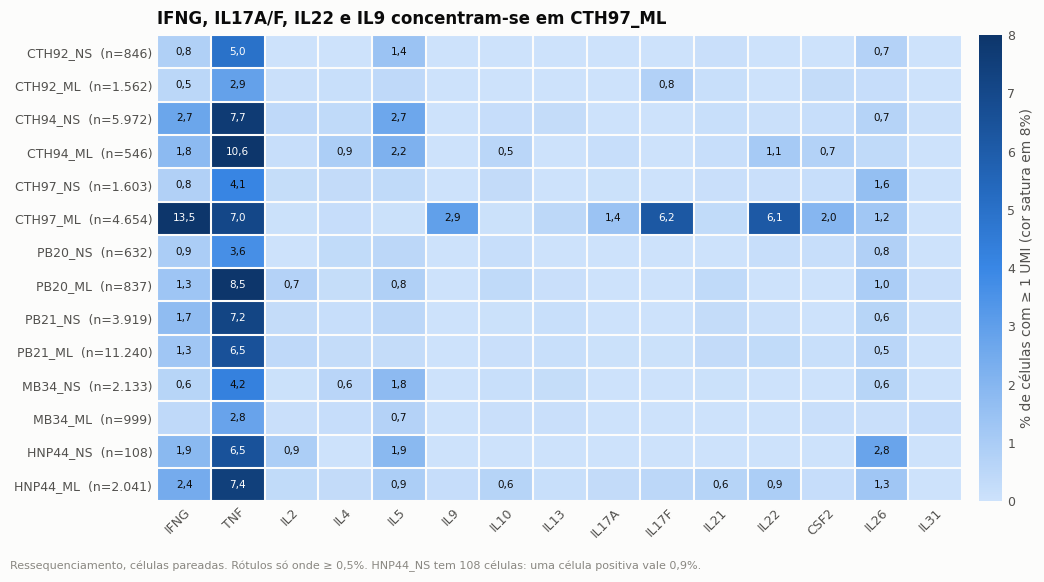

parcela das células positivas que está em CTH97_ML (13% das células pareadas):
  IL9 96%; IL17F 91%; IL17A 82%; IL22 80%; CSF2 67%; IFNG 56%; IL13 30%; IL26 21%; IL21 17%; TNF 14%; IL4 10%; IL10 3%; IL2 2%; IL5 1%; IL31 0%


In [23]:
# Por biblioteca, no ressequenciamento (todas as células pareadas da biblioteca)
ci = [panel_idx[g] for g in config.CYTOKINES]
pos_lib = pd.DataFrame(G["pos_new"][:, ci], index=LIBS, columns=config.CYTOKINES)
n_lib = ganho["pareadas"]
pct_lib = pos_lib.div(n_lib, axis=0) * 100
pct_lib_old = pd.DataFrame(G["pos_old"][:, ci], index=LIBS, columns=config.CYTOKINES).div(n_lib, axis=0) * 100
io.save_table(pos_lib.assign(celulas=n_lib), NB, "citocinas_positivas_por_biblioteca_nova",
              description="Células positivas por citocina e biblioteca no ressequenciamento (pareadas)")

cols = [g for g in config.CYTOKINES if pos_lib[g].sum() >= 10]
hm = pct_lib[cols].copy()
hm.index = [f"{l}  (n={F.n(n_lib[l])})" for l in hm.index]
fig, ax = plt.subplots(figsize=(10.5, 5.6))
plotting.heatmap(ax, hm, fmt=".1f", annotate_above=0.5, vmin=0, vmax=8,
                 cbar_label="% de células com ≥ 1 UMI (cor satura em 8%)")
ax.set_title("IFNG, IL17A/F, IL22 e IL9 concentram-se em CTH97_ML")
fig.tight_layout()
plotting.note(fig, "Ressequenciamento, células pareadas. Rótulos só onde ≥ 0,5%. "
                   "HNP44_NS tem 108 células: uma célula positiva vale 0,9%.")
plotting.savefig(fig, NB, "citocinas_por_biblioteca",
                 description="% de células positivas por citocina e biblioteca (ressequenciamento)",
                 data=pct_lib[cols])
plt.show()

share = (pos_lib.loc["CTH97_ML"] / pos_lib.sum()).reindex(cols)
print("parcela das células positivas que está em CTH97_ML "
      f"({F.pct(n_lib['CTH97_ML'] / n_lib.sum(), 0)} das células pareadas):")
print("  " + "; ".join(f"{g} {F.pct(v, 0)}" for g, v in share.sort_values(ascending=False).items()))

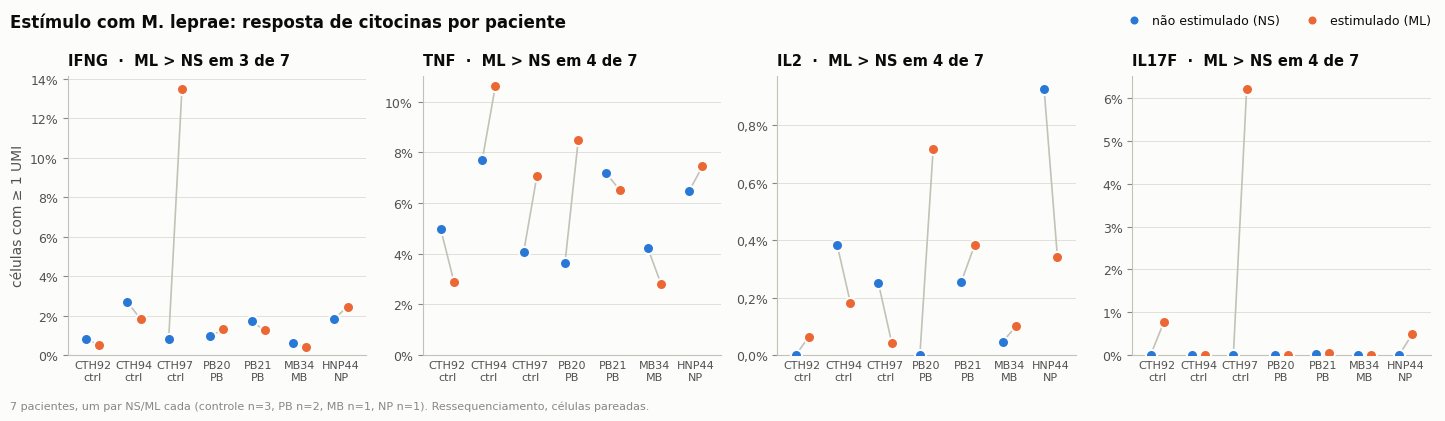

,mediana_NS,mediana_ML,pacientes_ML_maior,p_wilcoxon_exato
gene,,,,
IFNG,"0,95%","1,31%",3,"0,938"
TNF,"4,96%","7,05%",4,"0,375"
IL2,"0,25%","0,18%",4,"0,938"
IL17F,"0,00%","0,04%",4,"0,125"
IL22,"0,07%","0,34%",4,"0,125"
IL5,"1,42%","0,70%",1,"0,078"


In [24]:
# Estimulado × não estimulado dentro do paciente (n = 7 pares) — o único contraste com réplica
linhas = []
for g in ["IFNG", "TNF", "IL2", "IL17F", "IL22", "IL5"]:
    ns = pct_lib.loc[[f"{p}_NS" for p in config.PATIENTS], g].to_numpy()
    ml = pct_lib.loc[[f"{p}_ML" for p in config.PATIENTS], g].to_numpy()
    w = stats.wilcoxon(ml, ns, zero_method="wilcox", alternative="two-sided", method="exact") \
        if np.any(ml != ns) else None
    linhas.append({"gene": g, "mediana_NS": np.median(ns), "mediana_ML": np.median(ml),
                   "pacientes_ML_maior": int((ml > ns).sum()),
                   "p_wilcoxon_exato": w.pvalue if w is not None else np.nan})
estim = pd.DataFrame(linhas).set_index("gene")
io.save_table(estim, NB, "estimulo_pareado_citocinas",
              description="% de células positivas, estimulado × não estimulado pareado por paciente (n=7)")

fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.9))
for ax, g in zip(axes, ["IFNG", "TNF", "IL2", "IL17F"]):
    plotting.paired_dots(ax, pct_lib[g] / 100)
    plotting.percent(ax, decimals=0 if pct_lib[g].max() > 3 else 1)
    ax.set_ylim(0, None)
    ax.set_title(f"{g}  ·  ML > NS em {int(estim.loc[g, 'pacientes_ML_maior'])} de 7", fontsize=10.5)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("células com ≥ 1 UMI")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plotting.stim_legend(fig, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Estímulo com M. leprae: resposta de citocinas por paciente", x=0.01, y=0.985,
             ha="left", fontsize=12, fontweight="bold")
plotting.note(fig, "7 pacientes, um par NS/ML cada (controle n=3, PB n=2, MB n=1, NP n=1). "
                   "Ressequenciamento, células pareadas.")
plotting.savefig(fig, NB, "estimulo_pareado",
                 description="% de células positivas por citocina, NS × ML por paciente",
                 data=pct_lib[["IFNG", "TNF", "IL2", "IL17F"]])
plt.show()
F.styler(estim, {"mediana_NS": lambda v: F.f(v, 2) + "%", "mediana_ML": lambda v: F.f(v, 2) + "%",
                 "p_wilcoxon_exato": lambda v: F.f(v, 3)})

**Leitura.** O estímulo com *M. leprae* não produz, na maioria dos
pacientes, aumento visível da fração de células com transcrito de citocina:
em vários pares a biblioteca estimulada fica igual ou abaixo da não
estimulada. A exceção é CTH97_ML, que concentra a maior parte das células
positivas para IFNG, IL17A, IL17F, IL22 e IL9 do experimento inteiro — e é a
mesma biblioteca que C01 apontou como a de menor complexidade por célula.
Com 7 pares, o menor p bilateral possível no Wilcoxon exato é 0,016; o
teste é reportado, mas o que informa é o padrão por paciente.

Isso muda a pergunta. O gargalo não é detectar o transcrito nas células que
o produzem (elas têm dezenas de UMIs); é que **poucas células o produzem**
nesta preparação. Uma resposta antígeno-específica envolve uma fração
pequena das T CD4⁺, e a maioria das células aqui tem perfil naive (C01).

In [25]:
ifng = pct_lib["IFNG"]
log.add("CRITICAL", "citocinas — efeito do ressequenciamento",
        "a detecção de citocinas não melhorou de forma relevante",
        evidence="células positivas, antiga → nova, em "
                 f"{F.n(n_pares)} células pareadas: "
                 + "; ".join(f"{g} {F.n(cit.loc[g, 'pos_antiga'])}→{F.n(cit.loc[g, 'pos_nova'])}"
                             for g in ["IFNG", "IL4", "IL10", "IL13", "IL17A", "IL21"])
                 + f"; {F.pct(soma['ganhou_1umi'] / soma['ganhou'], 0)} das células que ganharam "
                   "positividade têm exatamente 1 UMI",
        impact="o problema que motivou o ressequenciamento permanece: as citocinas que definem "
               "subtipos continuam em menos de 1% das células",
        recommendation="tratar a frequência de células produtoras como limite biológico/"
                       "experimental desta preparação; para estudá-las, enriquecer (captura de "
                       "células secretoras, sorting por marcador de ativação) ou usar leitura "
                       "direcionada, não profundidade")
log.add("MAJOR", "CTH97_ML",
        "a resposta de citocinas do experimento está concentrada em uma única biblioteca",
        evidence=f"CTH97_ML tem {F.pct(n_lib['CTH97_ML'] / n_lib.sum(), 0)} das células pareadas e "
                 + "; ".join(f"{F.pct(share[g], 0)} das {g}⁺" for g in ["IFNG", "IL17F", "IL22", "IL9", "IL17A"])
                 + f"; IFNG⁺ em {F.f(ifng['CTH97_ML'], 1)}% das suas células contra "
                   f"{F.f(ifng.drop('CTH97_ML').min(), 1)}–{F.f(ifng.drop('CTH97_ML').max(), 1)}% nas demais",
        impact="qualquer análise de citocinas no objeto integrado descreve essencialmente "
               "CTH97_ML: sinal de citocina e identidade de biblioteca estão confundidos. É "
               "também a biblioteca de menor complexidade por célula",
        recommendation="reportar citocinas sempre por biblioteca; não inferir programa "
                       "efetor 'do estímulo' a partir do agregado; caracterizar CTH97_ML em A02")
log.add("MAJOR", "estímulo com M. leprae",
        "na maioria dos pacientes o estímulo não aumenta a fração de células com transcrito de citocina",
        evidence="; ".join(f"{g}: ML > NS em {int(r['pacientes_ML_maior'])}/7 pacientes, medianas "
                           f"{F.f(r['mediana_NS'], 2)}% → {F.f(r['mediana_ML'], 2)}%, Wilcoxon exato "
                           f"p = {F.f(r['p_wilcoxon_exato'], 3)}" for g, r in estim.loc[["IFNG", "TNF", "IL2"]].iterrows()),
        impact="sem resposta detectável no nível de transcrito, a baixa contagem de citocinas "
               "não é um problema de sequenciamento",
        recommendation="rever desenho do estímulo (dose, tempo até a coleta, presença de "
                       "células apresentadoras) antes de novos experimentos; n=7 pares, "
                       "interpretação descritiva")

## Problemas e conclusão

In [26]:
io.save_data(cells, NB, "celulas_pareadas",
             description="UMIs e genes por célula pareada nas duas corridas")
issues = log.save()
print(log.summary().to_string())
show(issues)

[io] inalterado, não regravado: celulas_pareadas.parquet
severity
CRITICAL    2
MAJOR       3
MINOR       3
INFO        1


severity,location,problem,evidence,impact,recommendation
CRITICAL,ganho do ressequenciamento,a profundidade adicional rendeu poucos UMIs por célula,"aumento de profundidade de 2,4× a 10,6× (mediana 3,9×); ganho mediano de UMIs por célula pareada de +4% a +48%, abaixo de +10% em 9/14 bibliotecas; genes por célula +4% a +28%","a corrida antiga já estava, segundo a estimativa, entre 65% e 99% de saturação; o objeto novo tem essencialmente a mesma informação por célula","tratar o ressequenciamento como réplica técnica de leitura, não como ganho de sensibilidade; não repetir a estratégia"
CRITICAL,citocinas — efeito do ressequenciamento,a detecção de citocinas não melhorou de forma relevante,"células positivas, antiga → nova, em 37.092 células pareadas: IFNG 977→1.121; IL4 82→105; IL10 50→60; IL13 56→69; IL17A 75→80; IL21 74→90; 95% das células que ganharam positividade têm exatamente 1 UMI",o problema que motivou o ressequenciamento permanece: as citocinas que definem subtipos continuam em menos de 1% das células,"tratar a frequência de células produtoras como limite biológico/experimental desta preparação; para estudá-las, enriquecer (captura de células secretoras, sorting por marcador de ativação) ou usar leitura direcionada, não profundidade"
MAJOR,chamada de células,o ressequenciamento não recuperou células; as poucas adicionais são barcodes de baixo conteúdo,"37.161 → 37.898 células (+2,0%); os 806 barcodes novos têm mediana de 569 UMIs contra 9.244 das células pareadas; PB21_NS concentra 347 deles","o número de células é fixado na captura; a profundidade só acrescenta barcodes na fronteira do limiar, que são candidatos a remoção no QC",não esperar ganho de células com sequenciamento; avaliar esses barcodes de baixa contagem em A02
MAJOR,CTH97_ML,a resposta de citocinas do experimento está concentrada em uma única biblioteca,"CTH97_ML tem 13% das células pareadas e 56% das IFNG⁺; 91% das IL17F⁺; 80% das IL22⁺; 96% das IL9⁺; 82% das IL17A⁺; IFNG⁺ em 13,5% das suas células contra 0,4–2,7% nas demais",qualquer análise de citocinas no objeto integrado descreve essencialmente CTH97_ML: sinal de citocina e identidade de biblioteca estão confundidos. É também a biblioteca de menor complexidade por célula,reportar citocinas sempre por biblioteca; não inferir programa efetor 'do estímulo' a partir do agregado; caracterizar CTH97_ML em A02
MAJOR,estímulo com M. leprae,na maioria dos pacientes o estímulo não aumenta a fração de células com transcrito de citocina,"IFNG: ML > NS em 3/7 pacientes, medianas 0,95% → 1,31%, Wilcoxon exato p = 0,938; TNF: ML > NS em 4/7 pacientes, medianas 4,96% → 7,05%, Wilcoxon exato p = 0,375; IL2: ML > NS em 4/7 pacientes, medianas 0,25% → 0,18%, Wilcoxon exato p = 0,938","sem resposta detectável no nível de transcrito, a baixa contagem de citocinas não é um problema de sequenciamento","rever desenho do estímulo (dose, tempo até a coleta, presença de células apresentadoras) antes de novos experimentos; n=7 pares, interpretação descritiva"
MINOR,data/raw_h5ad/CTH94_NS.h5ad,a cópia em h5ad da matriz antiga está corrompida em relação à fonte,"7.168 entradas e 9.406 UMIs a menos que em data/raw/CTH94_NS, em 25 genes vizinhos do cromossomo 16 (ATP2C2, ATP2C2-AS1, CDH13, CDH13-AS1, CDH13-AS2…); os valores perdidos são um trecho contíguo de 28.672 bytes = 7 blocos de 4 KiB zerados; as outras 13 cópias são idênticas à fonte",qualquer leitura de data/raw_h5ad feita depois de 15/07 vê esses genes zerados em CTH94_NS; blocos de disco não gravados (volume NTFS),regerar esse arquivo a partir de data/raw (esta análise não escreve em data/); verificar a saúde do disco; conferir por releitura toda gravação de h5ad
MINOR,corrida antiga — genes com contagem que não se reproduz,um conjunto pequeno de genes tinha milhares de UMIs na corrida antiga e quase desaparece no ressequenciamento,"85 genes com ≥ 200 UMIs perderam mais da metade (ex.: ZFPM2 11.803→3.536, ENSG00000222031 7.742→259, ENSG00000290778 7.232→332, ENSG00000233

## Conclusão

* As 14 bibliotecas são as mesmas, sem troca de amostra.
* O ressequenciamento não recuperou células e acrescentou poucos UMIs por
  célula, porque a corrida antiga já estava próxima da saturação.
* As citocinas não melhoraram. As de alta expressão por célula já eram
  detectadas; as de baixa expressão ganham eventos de 1 UMI, que têm taxa de
  falso positivo não desprezível.
* O sinal de citocina do experimento está em uma biblioteca (CTH97_ML), e o
  estímulo não mostra resposta na maioria dos pacientes.
* Alguns por cento das detecções de 1 UMI não se reproduzem entre corridas,
  e um conjunto pequeno de genes (TOX2 entre eles) tinha na corrida antiga
  uma contagem que não se confirma.

C03 examina as moléculas do ressequenciamento uma a uma: suporte de reads,
rarefação e o que mais profundidade ainda poderia render para as citocinas.

In [27]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

25 artefatos gravados por este notebook:
                                   name    kind
                      genes_antigo_novo parquet
                       celulas_pareadas parquet
                   integridade_raw_h5ad   table
                fig_identidade_barcodes  figure
                fig_identidade_barcodes   table
                     chamada_de_celulas   table
                     barcodes_so_antiga   table
                   ganho_por_biblioteca   table
                   fig_ganho_por_celula  figure
                   fig_ganho_por_celula   table
        reprodutibilidade_das_contagens   table
                   genes_que_colapsaram   table
           ganho_por_nivel_de_expressao   table
       fig_ganho_por_nivel_de_expressao  figure
       fig_ganho_por_nivel_de_expressao   table
                  citocinas_antigo_novo   table
              fig_citocinas_antigo_novo  figure
              fig_citocinas_antigo_novo   table
citocinas_positivas_por_biblioteca_nova   table